# What Drives the Price of a Used Car?

**Practical Application 2 – UC Berkeley Professional Certificate in Machine Learning & AI**

The client is a used-car dealership that wants to know **what consumers value in a used car** so it can fine-tune its inventory. This notebook follows the **CRISP-DM** process: Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment.

Data: a 426K-row extract of the Kaggle used-car listings dataset (`vehicles.csv.zip`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

## 1. Business Understanding

**Business objective:** identify the factors that make a used car more or less expensive, so the dealership can stock vehicles that command higher prices and price its inventory competitively.

**Data problem definition:** this is a **supervised regression** task. The target variable is the listing `price` (modelled as `log(price)` because prices are heavily right-skewed). The inputs are vehicle attributes: age (from `year`), `odometer`, `manufacturer`, `condition`, `cylinders`, `fuel`, `title_status`, `transmission`, `drive`, `size`, `type`, `paint_color` and `state`.

We will fit several regression models (linear, Ridge, Lasso, polynomial), select the best using **cross-validation**, and then **interpret the model's coefficients and feature importances** to explain which attributes drive price. The emphasis is on *inference* (understanding drivers) as much as *prediction* accuracy.

**Success criteria:** a model that clearly beats a naïve baseline on unseen data (lower RMSE, higher R²), and clear, actionable findings about price drivers for the dealership.

## 2. Data Understanding

In [2]:
df = pd.read_csv('vehicles.csv.zip')
print('Shape:', df.shape)
df.head()

Shape: (426880, 18)


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  str    
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  str    
 5   model         421603 non-null  str    
 6   condition     252776 non-null  str    
 7   cylinders     249202 non-null  str    
 8   fuel          423867 non-null  str    
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  str    
 11  transmission  424324 non-null  str    
 12  VIN           265838 non-null  str    
 13  drive         296313 non-null  str    
 14  size          120519 non-null  str    
 15  type          334022 non-null  str    
 16  paint_color   296677 non-null  str    
 17  state         426880 non-null  str    
dtypes: float64(2), 

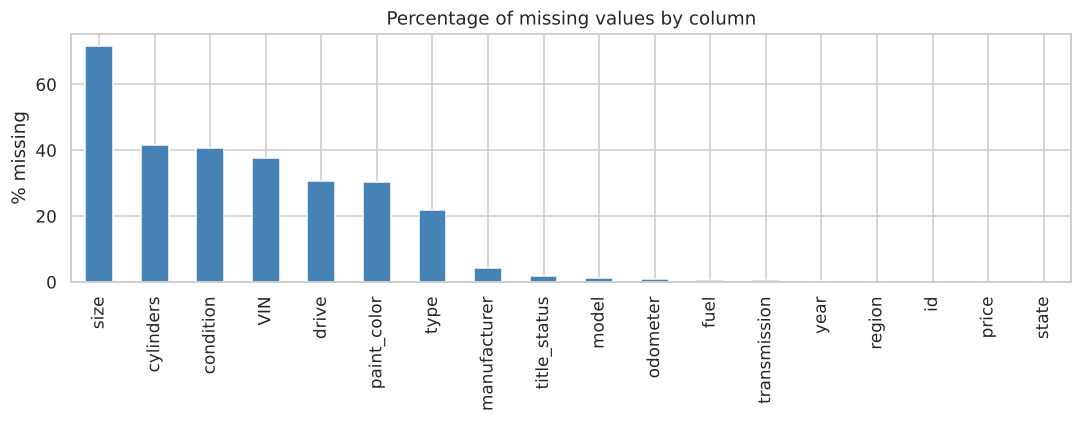

size            71.8
cylinders       41.6
condition       40.8
VIN             37.7
drive           30.6
paint_color     30.5
type            21.8
manufacturer     4.1
title_status     1.9
model            1.2
odometer         1.0
fuel             0.7
transmission     0.6
year             0.3
region           0.0
id               0.0
price            0.0
state            0.0
dtype: float64

In [4]:
# Share of missing values per column
missing = (df.isnull().mean() * 100).round(1).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
missing.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Percentage of missing values by column')
ax.set_ylabel('% missing')
plt.tight_layout(); plt.savefig('fig_missing_values.png', bbox_inches='tight'); plt.show()
missing

In [5]:
# Target variable: price
print(df['price'].describe(percentiles=[.01, .05, .5, .95, .99]).apply(lambda x: f'{x:,.0f}'))
print('\nListings with price = 0:', (df['price'] == 0).sum())
print('Duplicate listings (ignoring id):', df.drop(columns='id').duplicated().sum())

count          426,880
mean            75,199
std         12,182,282
min                  0
1%                   0
5%                   0
50%             13,950
95%             44,500
99%             66,995
max      3,736,928,711
Name: price, dtype: str

Listings with price = 0: 32895


Duplicate listings (ignoring id): 56202


In [6]:
# Cardinality of the categorical columns
df.select_dtypes('object').nunique().sort_values(ascending=False)

VIN             118246
model            29649
region             404
state               51
manufacturer        42
type                13
paint_color         12
cylinders            8
title_status         6
condition            6
fuel                 5
size                 4
drive                3
transmission         3
dtype: int64

**Data quality issues found**

- **Price has extreme errors:** about 7.7% of listings have a price of \$0, and the maximum is \$3.7 *billion*. Placeholders and typos need removing.
- **Heavy missingness** in `size` (72%), `cylinders` (42%), `condition` (41%), `VIN` (38%), `drive` and `paint_color` (~31%) and `type` (22%).
- **Duplicates:** around 56K listings are identical apart from `id` (the same car reposted).
- **Implausible values:** years back to 1900 and odometer readings up to 10 million miles.
- **Identifier and very high-cardinality columns** (`id`, `VIN`, `model` with ~29K values, `region` with 404) are not useful as general price drivers.

## 3. Data Preparation

In [7]:
cars = df.copy()

# 1. Drop identifiers / very high-cardinality text
cars = cars.drop(columns=['id', 'VIN', 'model', 'region'])

# 2. Remove duplicate listings
cars = cars.drop_duplicates()

# 3. Keep realistic prices, years and mileage
cars = cars[(cars['price'] >= 1_000) & (cars['price'] <= 100_000)]
cars = cars[(cars['year'] >= 1995) & (cars['year'] <= 2022)]
cars = cars[(cars['odometer'] > 0) & (cars['odometer'] <= 300_000)]

# 4. Feature engineering
cars['age'] = 2022 - cars['year']          # data was collected in 2021-22
cars = cars.drop(columns='year')
cars['log_price'] = np.log(cars['price'])

# 5. Missing categories become an explicit 'unknown' level (missingness itself can be informative)
cat_cols = ['manufacturer', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission',
            'drive', 'size', 'type', 'paint_color', 'state']
cars[cat_cols] = cars[cat_cols].fillna('unknown')

num_cols = ['age', 'odometer']
print('Rows after cleaning:', len(cars), f'({len(cars)/len(df):.0%} of original)')
print('Remaining missing values:', cars[cat_cols + num_cols].isnull().sum().sum())

Rows after cleaning: 250043 (59% of original)
Remaining missing values: 0


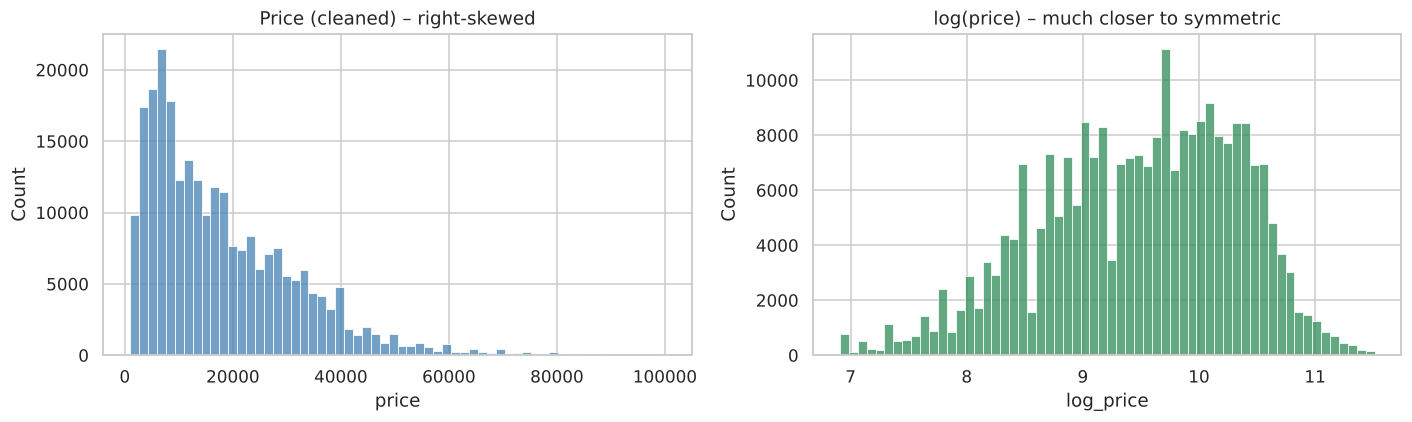

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(cars['price'], bins=60, ax=axes[0], color='steelblue')
axes[0].set_title('Price (cleaned) – right-skewed')
sns.histplot(cars['log_price'], bins=60, ax=axes[1], color='seagreen')
axes[1].set_title('log(price) – much closer to symmetric')
plt.tight_layout(); plt.savefig('fig_price_distribution.png', bbox_inches='tight'); plt.show()

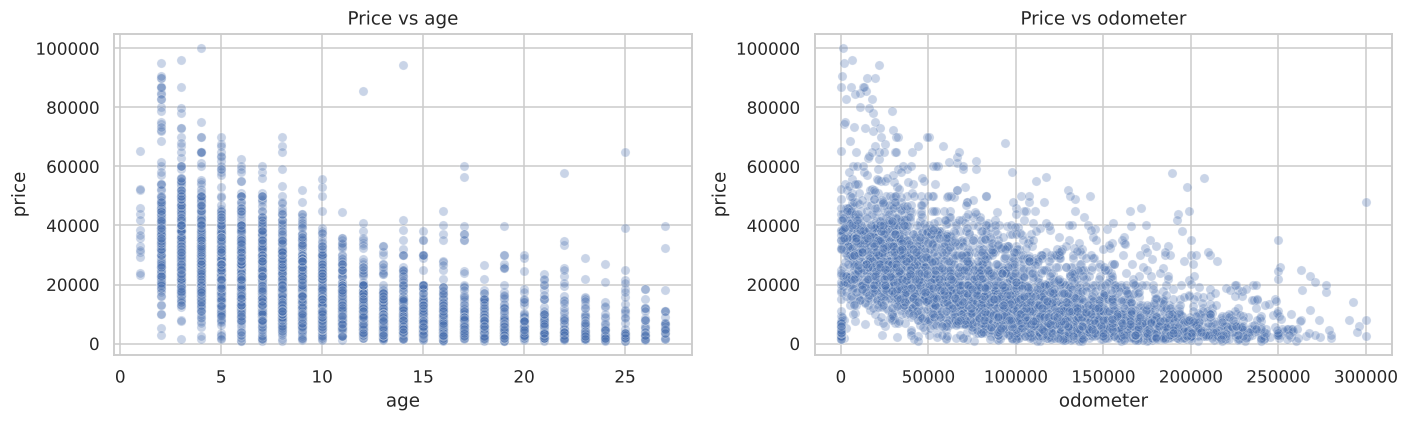

In [9]:
# How price relates to the two numeric drivers (sample for readability)
sample = cars.sample(5000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=sample, x='age', y='price', alpha=0.3, ax=axes[0])
axes[0].set_title('Price vs age')
sns.scatterplot(data=sample, x='odometer', y='price', alpha=0.3, ax=axes[1])
axes[1].set_title('Price vs odometer')
plt.tight_layout(); plt.savefig('fig_price_vs_age_odometer.png', bbox_inches='tight'); plt.show()

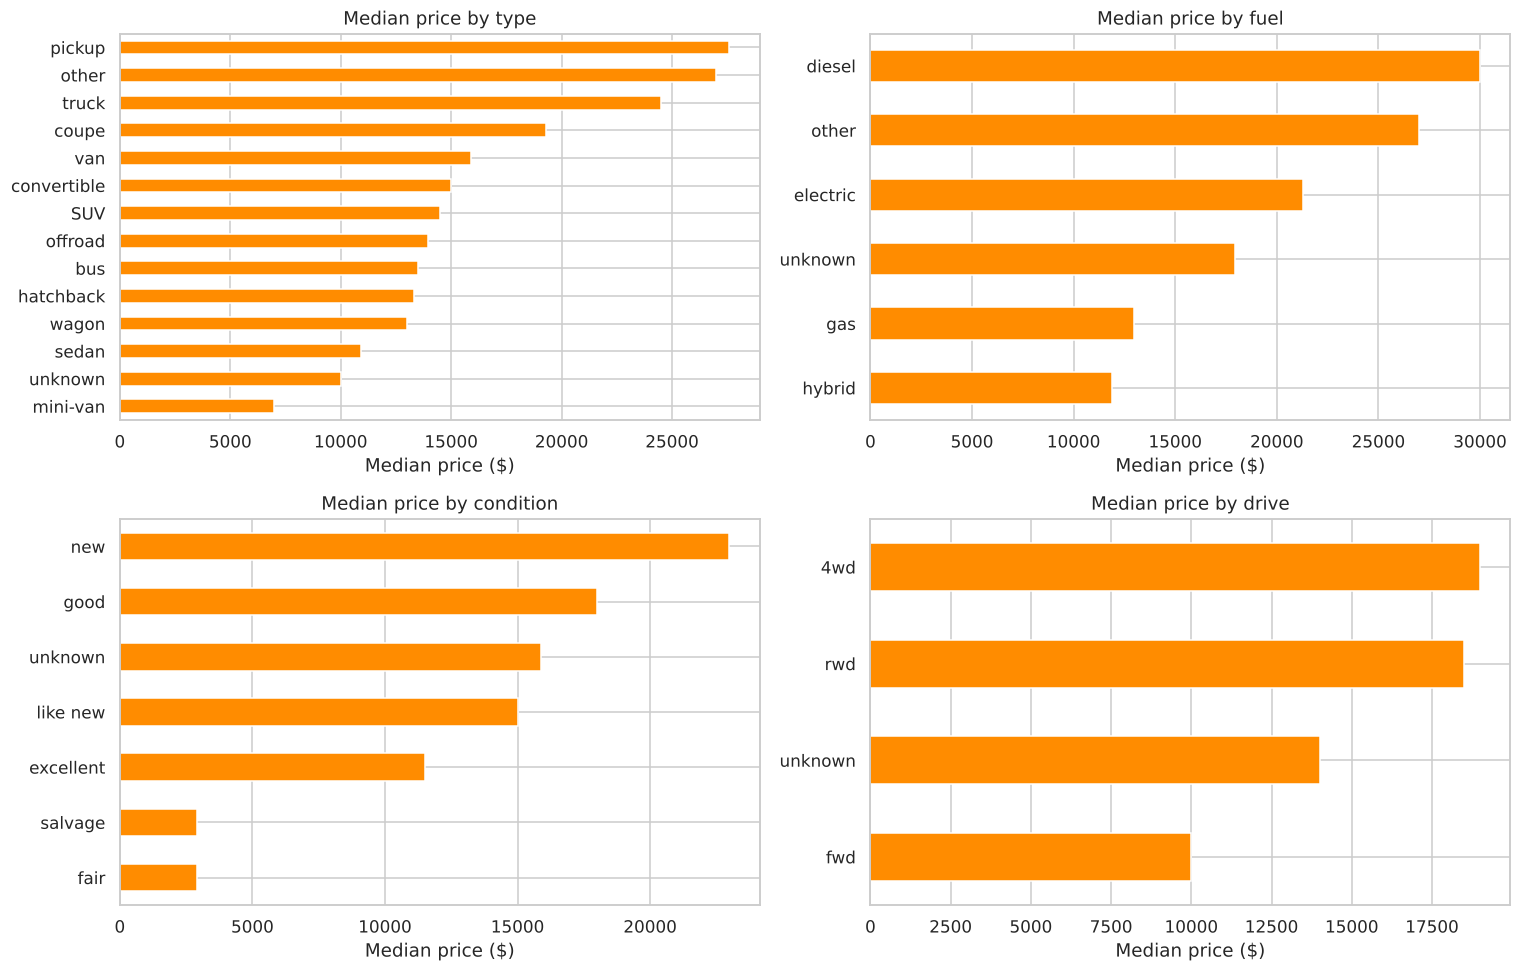

In [10]:
# Median price by key categorical features
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, ['type', 'fuel', 'condition', 'drive']):
    med = cars.groupby(col)['price'].median().sort_values()
    med.plot(kind='barh', ax=ax, color='darkorange')
    ax.set_title(f'Median price by {col}'); ax.set_xlabel('Median price ($)'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig('fig_median_price_by_category.png', bbox_inches='tight'); plt.show()

In [11]:
# Train / test split (the test set is only used once, for the final evaluation)
X = cars[num_cols + cat_cols]
y = cars['log_price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

# Shared preprocessing: scale numeric features, one-hot encode categoricals
def make_preprocessor(poly_degree=1):
    numeric = Pipeline([('poly', PolynomialFeatures(degree=poly_degree, include_bias=False)),
                        ('scale', StandardScaler())])
    return make_column_transformer(
        (numeric, num_cols),
        (OneHotEncoder(handle_unknown='ignore', min_frequency=50), cat_cols))

(200034, 13) (50009, 13)


## 4. Modeling

All models predict `log(price)`. Errors are reported back in **dollars** so they are meaningful to the client. Hyperparameters are chosen with **5-fold cross-validation** on the training set only.

Models compared:
1. **Baseline:** always predict the average price
2. **Simple linear regression:** age and odometer only
3. **Linear regression:** all features
4. **Ridge regression:** all features, alpha tuned with GridSearchCV
5. **Lasso regression:** all features, alpha tuned with GridSearchCV (also performs feature selection)
6. **Ridge + polynomial features:** adds squared/interaction terms for age and mileage to capture non-linear depreciation

**Evaluation metric:** the primary metric is **RMSE (root mean squared error)**, used on `log(price)` for cross-validation and model selection, and converted back to **dollars** for the client.
- *Why RMSE?* It is in the same units as price, so it's easy to explain ("typical error of about $X"). Because it squares errors, it penalises large mispricings heavily, which matters to a dealer, since a badly overpriced or underpriced car is costly.
- *Why on log price?* Price errors scale with price (a \$2,000 error matters more on a \$5,000 car than on a \$60,000 truck). Working in logs treats errors as percentages and stops expensive vehicles dominating the fit.
- MAE (in dollars) and R² are reported as supporting metrics.

In [12]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}

def dollar_metrics(model, X_, y_):
    pred = np.exp(model.predict(X_)); actual = np.exp(y_)
    return {'RMSE ($)': np.sqrt(mean_squared_error(actual, pred)),
            'MAE ($)': mean_absolute_error(actual, pred),
            'R² (log price)': r2_score(y_, model.predict(X_))}

def evaluate(name, model):
    cv_rmse = -cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error').mean()
    model.fit(X_train, y_train)
    results[name] = {'CV RMSE (log)': cv_rmse, **{f'Test {k}': v for k, v in dollar_metrics(model, X_test, y_test).items()}}
    return model

baseline = evaluate('Baseline (mean)', DummyRegressor())
simple_lr = evaluate('Linear: age + odometer', Pipeline([
    ('prep', make_column_transformer((StandardScaler(), num_cols))), ('lr', LinearRegression())]))
full_lr = evaluate('Linear: all features', Pipeline([('prep', make_preprocessor()), ('lr', LinearRegression())]))
pd.DataFrame(results).T.round(3)

,CV RMSE (log),Test RMSE ($),Test MAE ($),Test R² (log price)
Baseline (mean),0.853,14788.010,10653.413,-0.000
Linear: age + odometer,0.590,10576.964,6982.295,0.522
Linear: all features,0.414,7525.047,4571.887,0.763


In [13]:
# Ridge: tune alpha with GridSearchCV
ridge_grid = GridSearchCV(Pipeline([('prep', make_preprocessor()), ('ridge', Ridge())]),
                          param_grid={'ridge__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
                          cv=kf, scoring='neg_root_mean_squared_error')
ridge_grid.fit(X_train, y_train)
print('Best Ridge alpha:', ridge_grid.best_params_)
ridge = evaluate('Ridge (tuned)', ridge_grid.best_estimator_)

# Lasso: tune alpha (on a 50K training sample for speed)
lasso_sample = X_train.sample(50_000, random_state=RANDOM_STATE)
lasso_grid = GridSearchCV(Pipeline([('prep', make_preprocessor()), ('lasso', Lasso(max_iter=5000))]),
                          param_grid={'lasso__alpha': [0.0001, 0.001, 0.01, 0.1]},
                          cv=kf, scoring='neg_root_mean_squared_error')
lasso_grid.fit(lasso_sample, y_train.loc[lasso_sample.index])
print('Best Lasso alpha:', lasso_grid.best_params_)
lasso = evaluate('Lasso (tuned)', lasso_grid.best_estimator_)

# Ridge with polynomial terms on the numeric features
poly_grid = GridSearchCV(Pipeline([('prep', make_preprocessor(poly_degree=2)), ('ridge', Ridge())]),
                         param_grid={'prep__pipeline__poly__degree': [2, 3], 'ridge__alpha': [1, 10, 100]},
                         cv=kf, scoring='neg_root_mean_squared_error')
poly_grid.fit(X_train, y_train)
print('Best polynomial Ridge:', poly_grid.best_params_)
poly_ridge = evaluate('Ridge + polynomial (tuned)', poly_grid.best_estimator_)

results_df = pd.DataFrame(results).T
results_df.round(3)

Best Ridge alpha: {'ridge__alpha': 0.1}


Best Lasso alpha: {'lasso__alpha': 0.0001}


Best polynomial Ridge: {'prep__pipeline__poly__degree': 3, 'ridge__alpha': 1}


,CV RMSE (log),Test RMSE ($),Test MAE ($),Test R² (log price)
Baseline (mean),0.853,14788.010,10653.413,-0.000
Linear: age + odometer,0.590,10576.964,6982.295,0.522
Linear: all features,0.414,7525.047,4571.887,0.763
Ridge (tuned),0.414,7527.604,4572.171,0.763
Lasso (tuned),0.414,7531.316,4567.064,0.763
Ridge + polynomial (tuned),0.406,7465.077,4512.595,0.772


## 5. Evaluation

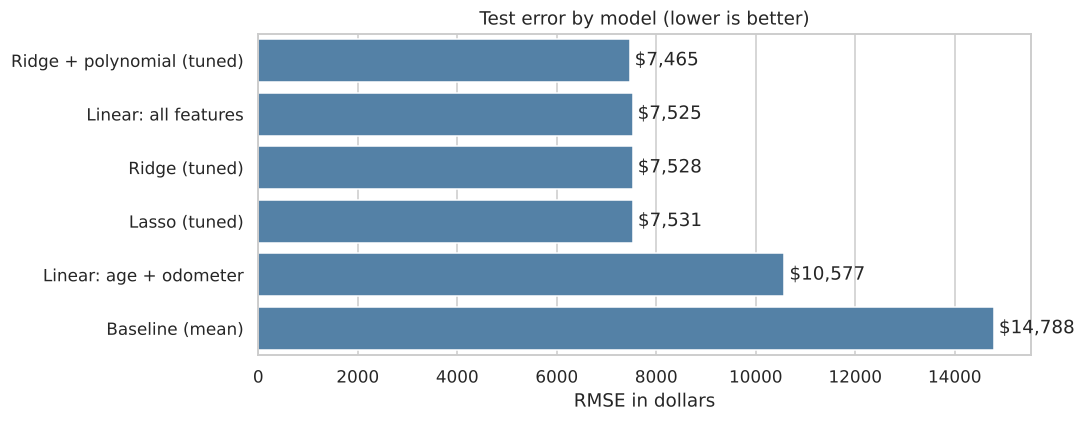

Best model by cross-validation: Ridge + polynomial (tuned)


In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_df = results_df.sort_values('Test RMSE ($)')
sns.barplot(x=plot_df['Test RMSE ($)'], y=plot_df.index, ax=ax, color='steelblue')
for i, v in enumerate(plot_df['Test RMSE ($)']):
    ax.text(v + 100, i, f'${v:,.0f}', va='center')
ax.set_title('Test error by model (lower is better)'); ax.set_xlabel('RMSE in dollars'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig('fig_model_comparison.png', bbox_inches='tight'); plt.show()

best_name = results_df['CV RMSE (log)'].idxmin()
best_model = {'Ridge (tuned)': ridge, 'Lasso (tuned)': lasso,
              'Ridge + polynomial (tuned)': poly_ridge, 'Linear: all features': full_lr}.get(best_name, poly_ridge)
print('Best model by cross-validation:', best_name)

**Interpreting the coefficients.** Because the target is `log(price)`, each coefficient translates into a **percentage effect on price**: `exp(coef) − 1`. For one-hot features the effect is relative to other categories of the same feature, and for the scaled numeric features it is the effect of a one-standard-deviation increase. We use the tuned **Ridge** model (no polynomial terms) for this, because its coefficients are directly readable.

Each extra 5.7 years of age changes price by -34.9%
Each extra 62,495 miles changes price by -20.9%


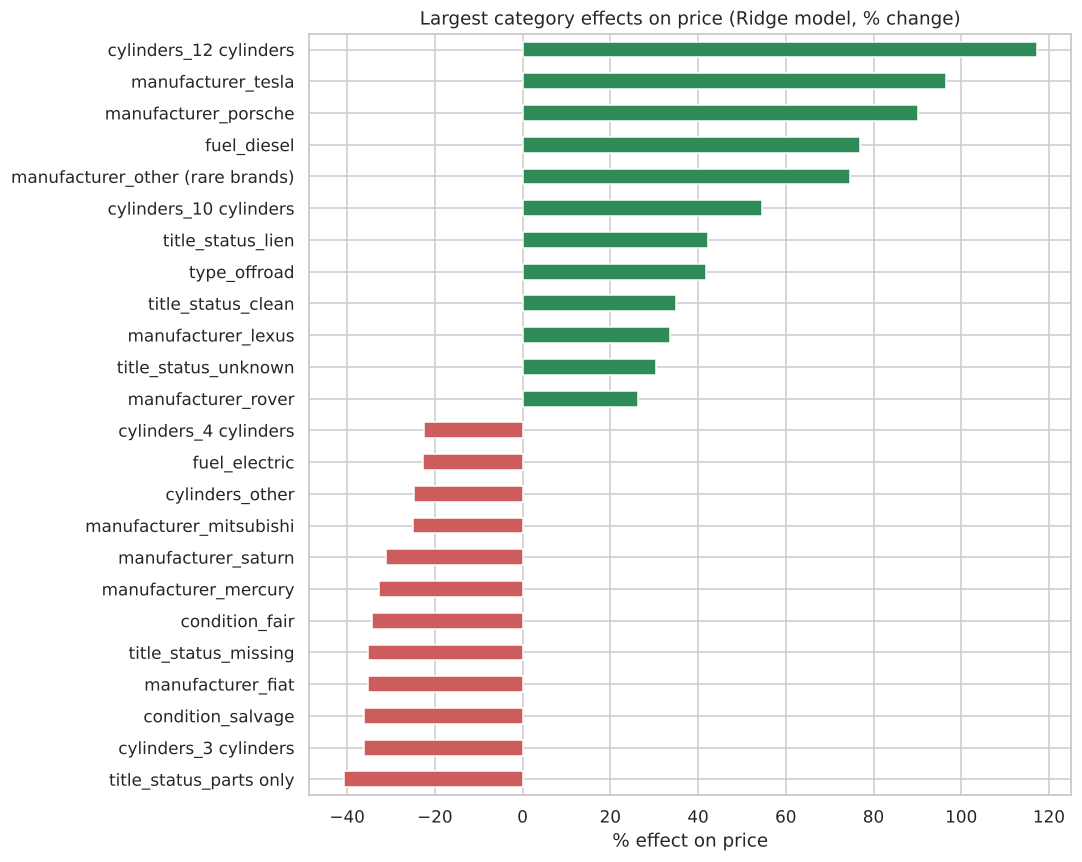

In [15]:
prep = ridge.named_steps['prep']
names = prep.get_feature_names_out()
coefs = pd.Series(ridge.named_steps['ridge'].coef_, index=names)
pct = (np.exp(coefs) - 1) * 100
clean = pct.rename(lambda s: s.replace('pipeline__', '').replace('standardscaler__', '').replace('onehotencoder__', '').replace('infrequent_sklearn', 'other (rare brands)'))

# Numeric effects
std_age, std_odo = X_train['age'].std(), X_train['odometer'].std()
print(f"Each extra {std_age:.1f} years of age changes price by {clean['age']:.1f}%")
print(f"Each extra {std_odo:,.0f} miles changes price by {clean['odometer']:.1f}%")

top = pd.concat([clean.drop(['age', 'odometer']).nlargest(12), clean.drop(['age', 'odometer']).nsmallest(12)]).sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
top.plot(kind='barh', ax=ax, color=['indianred' if v < 0 else 'seagreen' for v in top])
ax.set_title('Largest category effects on price (Ridge model, % change)'); ax.set_xlabel('% effect on price')
plt.tight_layout(); plt.savefig('fig_coefficient_effects.png', bbox_inches='tight'); plt.show()

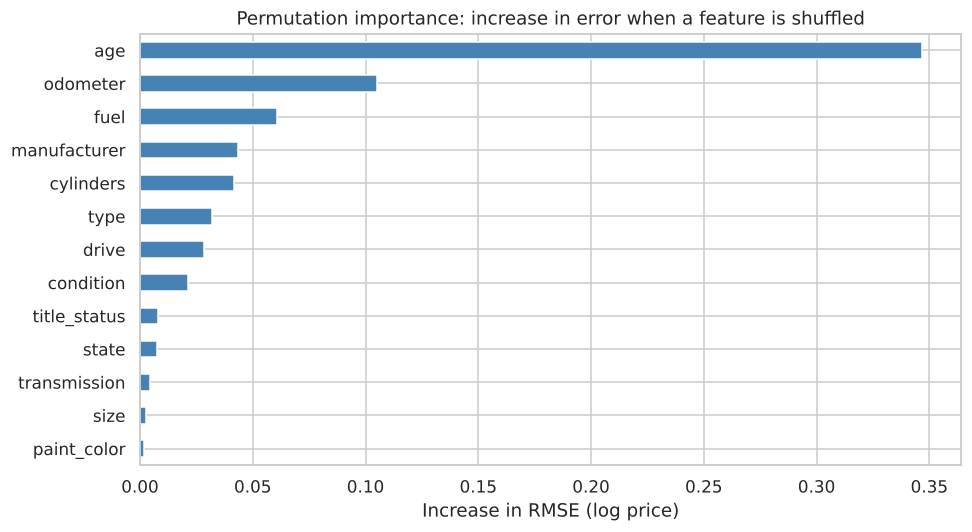

age             0.3469
odometer        0.1050
fuel            0.0606
manufacturer    0.0433
cylinders       0.0415
type            0.0321
drive           0.0284
condition       0.0211
title_status    0.0081
state           0.0075
transmission    0.0044
size            0.0027
paint_color     0.0020
dtype: float64

In [16]:
# Which feature *groups* matter most? Permutation importance on a 20K test sample
pi_sample = X_test.sample(20_000, random_state=RANDOM_STATE)
pi = permutation_importance(best_model, pi_sample, y_test.loc[pi_sample.index],
                            n_repeats=3, random_state=RANDOM_STATE, scoring='neg_root_mean_squared_error')
importance = pd.Series(pi.importances_mean, index=pi_sample.columns).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
importance.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Permutation importance: increase in error when a feature is shuffled'); ax.set_xlabel('Increase in RMSE (log price)')
plt.tight_layout(); plt.savefig('fig_feature_importance.png', bbox_inches='tight'); plt.show()
importance.sort_values(ascending=False).round(4)

**Evaluation summary**

| Model | Test RMSE ($) | Test MAE ($) | Test R² (log price) |
|---|---|---|---|
| Baseline (always predict the mean) | 14,788 | 10,653 | 0.00 |
| Linear: age + odometer only | 10,577 | 6,982 | 0.52 |
| Linear / Ridge / Lasso: all features | ~7,530 | ~4,570 | 0.76 |
| **Ridge + polynomial (degree 3), best** | **7,465** | **4,513** | **0.77** |

- **The best model roughly halves the baseline error.** Typical pricing error falls from about \$14,800 to about \$7,500 (RMSE), and the model explains **77%** of the variation in log price on unseen data.
- **Cross-validated and test results agree closely**, so the models generalise and are **not overfitting**.
- **Regularisation barely changes accuracy:** grid search picked a small Ridge alpha (0.1) and a tiny Lasso alpha. With 200K training rows and only about 150 features there is little overfitting to correct. **Polynomial terms** give the best result by capturing the curved way cars lose value with age and mileage.
- **Interpreting the coefficients:** holding everything else constant, a car **5.7 years older loses about 35%** of its price, and **62,500 extra miles costs about 21%**.
- **The remaining error** reflects what the data lacks: exact model and trim, options, accident history and photos.

The business question is answered with useful confidence, so we proceed to deployment.

## 6. Deployment – Findings for the Dealership

**What drives used-car prices, in order of importance** (from permutation importance and the model coefficients):

1. **Age is by far the biggest driver, followed by mileage.** Each additional ~6 years of age cuts price by about **35%**, and each additional ~62,500 miles by about **21%**, holding everything else equal. *Action: prioritise newer, lower-mileage stock, ideally a few years old with below-average miles.*
2. **Fuel type:** **diesel** vehicles sell for about **77% more** than comparable gas vehicles. *Action: diesel trucks are a high-value segment worth seeking out.*
3. **Brand:** **Tesla, Porsche, Lexus and Land Rover** carry large premiums, while **Fiat, Mercury, Saturn and Mitsubishi** trade at a 25–35% discount. *Action: use brand effects to guide trade-in offers and list prices.*
4. **Engine size:** 10- and 12-cylinder vehicles command big premiums, and **4- and 3-cylinder cars sell for 22–36% less**.
5. **Vehicle type and drivetrain:** **pickups and trucks** have the highest median prices, mini-vans and sedans the lowest, and **4WD** vehicles are worth more than front-wheel drive. *Action: weight inventory towards trucks, pickups and 4WD.*
6. **Condition and title:** cars in **fair or salvage condition lose about 35%**, and **parts-only or missing titles cost 35–40%**. Differences among good, excellent and like-new are small. *Action: avoid damaged and branded-title stock unless it's bought very cheaply.*
7. **Paint colour, size and transmission matter very little.** *Action: don't pay extra for cosmetic features.*

**Recommendations**
- Use the model as a **pricing-guidance tool** when valuing trade-ins and setting list prices, flagging cars priced far from what comparable vehicles fetch.
- **Focus inventory** on newer, low-mileage **trucks, pickups, 4WD and diesel** vehicles with clean titles, and on premium brands.
- **Capture better data at intake** (model and trim, options, service and accident history) to sharpen price estimates.

**Next steps:** add model and trim information (for example with target encoding), test tree-based and ensemble models covered later in the program, and retrain regularly as market prices shift.